### Dataset is divided into a training set and a testing set, containing numerical features that represent molecular properties and structural characteristics of drugs. The dataset supports predictive modeling tasks aimed at identifying `potential autoimmune risks` associated with drug candidates.

Thus, Problem statement is: *`Classification/Prediction of a candidate who might be at risk of potential autoimmune disease`*

In [37]:
import numpy as np 
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [38]:
train = pd.read_csv('drug_induced_autoimmunity_prediction/DIA_trainingset_RDKit_descriptors.csv')
test = pd.read_csv ('drug_induced_autoimmunity_prediction/DIA_testset_RDKit_descriptors.csv')

<>:1: SyntaxWarning:

invalid escape sequence '\D'

<>:2: SyntaxWarning:

invalid escape sequence '\D'

<>:1: SyntaxWarning:

invalid escape sequence '\D'

<>:2: SyntaxWarning:

invalid escape sequence '\D'

C:\Users\rudra\AppData\Local\Temp\ipykernel_4564\709356961.py:1: SyntaxWarning:

invalid escape sequence '\D'

C:\Users\rudra\AppData\Local\Temp\ipykernel_4564\709356961.py:2: SyntaxWarning:

invalid escape sequence '\D'



In [39]:
train

,Label,SMILES,BalabanJ,BertzCT,Chi0,Chi0n,Chi0v,Chi1,Chi1n,Chi1v,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,0,COC(=O)N(C)c1c(N)nc(nc1N)c2nn(Cc3ccccc3F)c4ncc...,1.821,1266.407,22.121,16.781,16.781,14.901,9.203,9.203,...,0,0,0,0,0,0,0,0,0,0
1,0,C[C@H](N(O)C(=O)N)c1cc2ccccc2s1,2.363,490.434,11.707,8.752,9.569,7.592,4.854,5.670,...,0,0,0,0,0,0,0,1,0,1
2,0,C[N+](C)(C)CC(=O)[O-],3.551,93.092,6.784,5.471,5.471,3.417,2.420,2.420,...,0,0,0,0,0,0,0,0,0,0
3,1,CC(C)n1c(\C=C\[C@H](O)C[C@H](O)CC(=O)O)c(c2ccc...,2.076,1053.003,21.836,16.995,16.995,14.274,9.926,9.926,...,0,0,0,0,0,0,0,0,0,0
4,1,C\C(=C(\C#N)/C(=O)Nc1ccc(cc1)C(F)(F)F)\O,2.888,549.823,14.629,9.746,9.746,8.752,5.040,5.040,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
472,0,C(C1=NCCN1)c2cccc3ccccc23,2.022,537.932,10.795,9.110,9.110,7.933,5.672,5.672,...,0,0,0,0,0,0,0,0,0,0
473,0,C[N@+]1(CC2CC2)CC[C@]34[C@H]5Oc6c(O)ccc(C[C@@H...,1.602,848.658,17.897,15.202,15.202,12.389,10.003,10.003,...,0,0,0,0,0,0,0,0,0,0
474,1,CO\N=C(/C(=O)N[C@H]1[C@H]2SCC(=C(N2C1=O)C(=O)O...,1.766,910.031,21.129,14.986,15.802,13.845,8.129,9.178,...,1,0,0,0,0,0,0,0,0,0
475,0,Clc1ccc(CO\N=C(\Cn2ccnc2)/c3ccc(Cl)cc3Cl)c(Cl)c1,1.831,926.191,18.518,13.372,16.396,12.525,7.566,9.078,...,0,0,0,0,0,0,0,0,0,0


In [40]:
test

,Label,SMILES,BalabanJ,BertzCT,Chi0,Chi0n,Chi0v,Chi1,Chi1n,Chi1v,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,0,C[C@H](\C=C\[C@H](O)C1CC1)[C@@H]2CC[C@@H]3\C(=...,1.484,743.207,21.466,18.764,18.764,14.292,12.106,12.106,...,0,0,0,0,0,0,0,0,0,0
1,1,OCCN1CCN(CCCN2c3ccccc3Sc4ccc(cc24)C(F)(F)F)CC1,1.472,868.947,21.140,16.736,17.553,14.453,10.268,11.084,...,0,0,0,0,0,0,0,0,0,0
2,0,C[C@@H]1O[C@H](C[C@H](O)[C@@H]1O)O[C@@H]2[C@H]...,0.837,1409.004,39.189,32.904,32.904,26.011,20.941,20.941,...,0,0,0,0,0,0,0,0,0,0
3,1,NC(=O)Cc1cccc(C(=O)c2ccccc2)c1N,2.406,621.298,13.828,10.297,10.297,9.092,5.847,5.847,...,0,0,0,0,0,0,0,0,0,0
4,0,COc1cc2c(CCN[C@]23CS[C@@H]4[C@@H]5[C@@H]6N(C)[...,1.320,2127.996,37.955,30.849,31.666,25.910,18.066,19.115,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,0,CCN1CCN(C(=O)N[C@H](C(=O)N[C@@H]2[C@@H]3SC(C)(...,1.508,1127.109,26.361,19.925,20.742,16.973,11.450,12.330,...,1,0,0,0,0,0,0,0,0,1
116,0,CC1=C(C=C(C#N)C(=O)N1)c2ccncc2,2.678,608.396,11.544,8.689,8.689,7.720,4.765,4.765,...,0,0,0,0,0,0,0,0,0,0
117,0,CCCN(CCc1cccs1)[C@@H]2CCc3c(O)cccc3C2,1.670,593.488,15.364,13.294,14.110,10.775,8.338,9.217,...,0,0,0,0,0,0,0,1,0,0
118,0,COCCOC(=O)C1=C(C)NC(=C([C@@H]1c2cccc(c2)[N+](=...,2.603,902.371,22.422,17.683,17.683,14.167,9.469,9.469,...,0,0,0,0,0,0,0,0,1,0


- Description file says `196` columns
- Link to the actual dataset says `195` features
- The data contains `198` features


Label for sure is the target column, what about SMILES?

In [41]:
train.Label.value_counts()

Label
0    359
1    118
Name: count, dtype: int64

In [42]:
test.Label.value_counts()

Label
0    90
1    30
Name: count, dtype: int64

In [43]:
Xtrain = train.drop(['Label','SMILES'], axis=1)
Xtest = test.drop(['Label','SMILES'], axis=1)

Ytrain = train['Label']
Ytest = test['Label']

In [44]:
Xtrain

,BalabanJ,BertzCT,Chi0,Chi0n,Chi0v,Chi1,Chi1n,Chi1v,Chi2n,Chi2v,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,1.821,1266.407,22.121,16.781,16.781,14.901,9.203,9.203,6.668,6.668,...,0,0,0,0,0,0,0,0,0,0
1,2.363,490.434,11.707,8.752,9.569,7.592,4.854,5.670,3.545,4.661,...,0,0,0,0,0,0,0,1,0,1
2,3.551,93.092,6.784,5.471,5.471,3.417,2.420,2.420,2.820,2.820,...,0,0,0,0,0,0,0,0,0,0
3,2.076,1053.003,21.836,16.995,16.995,14.274,9.926,9.926,7.662,7.662,...,0,0,0,0,0,0,0,0,0,0
4,2.888,549.823,14.629,9.746,9.746,8.752,5.040,5.040,3.601,3.601,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
472,2.022,537.932,10.795,9.110,9.110,7.933,5.672,5.672,4.070,4.070,...,0,0,0,0,0,0,0,0,0,0
473,1.602,848.658,17.897,15.202,15.202,12.389,10.003,10.003,9.607,9.607,...,0,0,0,0,0,0,0,0,0,0
474,1.766,910.031,21.129,14.986,15.802,13.845,8.129,9.178,5.826,6.931,...,1,0,0,0,0,0,0,0,0,0
475,1.831,926.191,18.518,13.372,16.396,12.525,7.566,9.078,5.406,7.094,...,0,0,0,0,0,0,0,0,0,0


In [45]:
Ytrain

0      0
1      0
2      0
3      1
4      1
      ..
472    0
473    0
474    1
475    0
476    1
Name: Label, Length: 477, dtype: int64

In [46]:
Xtest.shape , Ytest.shape

((120, 196), (120,))

In [47]:
print(Xtrain.isnull().sum().sum())
print(Xtest.isnull().sum().sum())
print(Ytest.isnull().sum().sum())
print(Ytrain.isnull().sum().sum())

0
0
0
0


In [48]:
scaler = StandardScaler()

In [49]:
Xtrain_scaled = scaler.fit_transform(Xtrain)
Xtest_scaled  = scaler.transform(Xtest)

Xtrain_scaled_df = pd.DataFrame(Xtrain_scaled, columns=Xtrain.columns)
Xtest_scaled_df  = pd.DataFrame(Xtest_scaled,  columns=Xtest.columns)

print('Xtrain_scaled shape:', Xtrain_scaled_df.shape)
print('Xtest_scaled  shape:', Xtest_scaled_df.shape)
Xtrain_scaled_df.describe().head(10)

Xtrain_scaled shape: (477, 196)
Xtest_scaled  shape: (120, 196)


,BalabanJ,BertzCT,Chi0,Chi0n,Chi0v,Chi1,Chi1n,Chi1v,Chi2n,Chi2v,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
count,4.770000e+02,4.770000e+02,4.770000e+02,4.770000e+02,4.770000e+02,4.770000e+02,4.770000e+02,4.770000e+02,4.770000e+02,4.770000e+02,...,4.770000e+02,4.770000e+02,4.770000e+02,4.770000e+02,4.770000e+02,4.770000e+02,477.0,4.770000e+02,4.770000e+02,4.770000e+02
mean,-3.007145e-16,6.144631e-17,-7.261836e-17,-2.234411e-17,1.750289e-16,3.575058e-16,2.029590e-16,-6.330832e-17,1.117206e-17,-2.383372e-16,...,1.005485e-16,6.144631e-17,-4.096420e-17,2.234411e-17,4.282621e-17,-5.027425e-17,0.0,2.886114e-17,-7.448037e-18,1.862009e-17
std,1.001050e+00,1.001050e+00,1.001050e+00,1.001050e+00,1.001050e+00,1.001050e+00,1.001050e+00,1.001050e+00,1.001050e+00,1.001050e+00,...,1.001050e+00,1.001050e+00,1.001050e+00,1.001050e+00,1.001050e+00,1.001050e+00,0.0,1.001050e+00,1.001050e+00,1.001050e+00
min,-1.628648e+00,-1.861214e+00,-2.032683e+00,-2.077580e+00,-2.147765e+00,-2.102610e+00,-2.084693e+00,-2.192054e+00,-1.958522e+00,-2.098884e+00,...,-2.226700e-01,-2.047919e-01,-1.220394e-01,-7.955573e-02,-9.196010e-02,-1.689343e-01,0.0,-1.555353e-01,-2.384920e-01,-1.673835e-01
25%,-6.528267e-01,-6.250703e-01,-6.526535e-01,-6.540196e-01,-6.729495e-01,-6.530730e-01,-7.001374e-01,-6.886210e-01,-6.932580e-01,-6.960307e-01,...,-2.226700e-01,-2.047919e-01,-1.220394e-01,-7.955573e-02,-9.196010e-02,-1.689343e-01,0.0,-1.555353e-01,-2.384920e-01,-1.673835e-01
50%,-2.515148e-01,-6.675942e-02,-6.685564e-02,-3.094502e-02,-3.328621e-02,-2.159582e-02,-2.211812e-02,8.763883e-03,-9.462855e-02,-4.000717e-02,...,-2.226700e-01,-2.047919e-01,-1.220394e-01,-7.955573e-02,-9.196010e-02,-1.689343e-01,0.0,-1.555353e-01,-2.384920e-01,-1.673835e-01
75%,3.891762e-01,5.210989e-01,5.417332e-01,5.515550e-01,5.432267e-01,5.458215e-01,5.740805e-01,5.680891e-01,5.738359e-01,5.983346e-01,...,-2.226700e-01,-2.047919e-01,-1.220394e-01,-7.955573e-02,-9.196010e-02,-1.689343e-01,0.0,-1.555353e-01,-2.384920e-01,-1.673835e-01
max,4.140386e+00,4.310994e+00,4.418690e+00,3.959328e+00,4.071329e+00,4.072018e+00,3.926332e+00,4.062100e+00,3.866755e+00,3.704631e+00,...,7.947606e+00,7.935685e+00,8.194075e+00,1.256981e+01,1.087428e+01,1.057529e+01,0.0,1.125837e+01,1.288774e+01,5.974304e+00


## PCA: 2D Projection of the Training Set
We reduce the 196 scaled features to 2 principal components and colour each point by its known label (0 = Non-DIA, 1 = DIA). This lets us visually inspect whether the two classes occupy distinct regions of feature space — which in turn informs whether K-Means is likely to recover label-aligned clusters.

PC1 explains 20.0%  |  PC2 explains 7.0%  |  Total: 27.0%


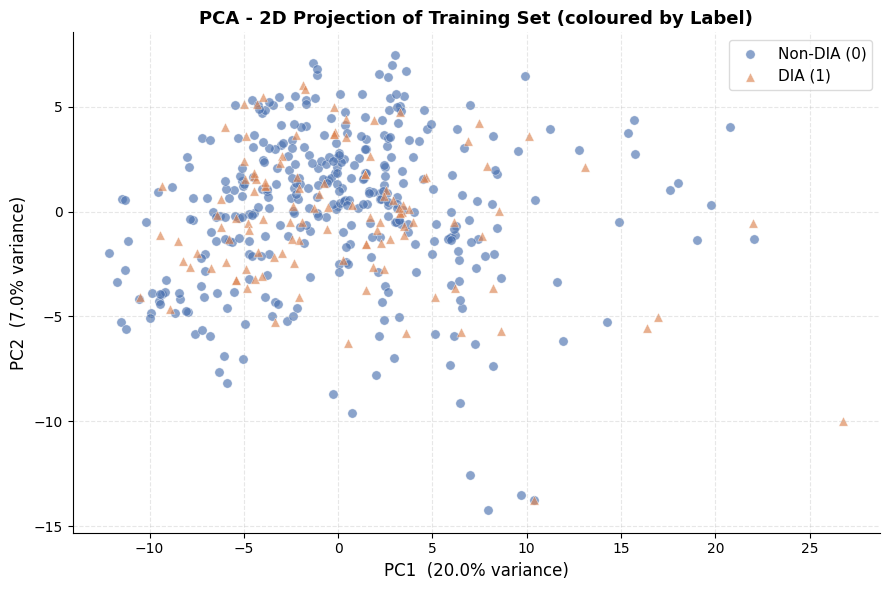

In [50]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(Xtrain_scaled_df)

var_exp = pca.explained_variance_ratio_ * 100
print(f'PC1 explains {var_exp[0]:.1f}%  |  PC2 explains {var_exp[1]:.1f}%  |  Total: {var_exp.sum():.1f}%')

fig, ax = plt.subplots(figsize=(9, 6))

colors  = {0: '#4C72B0', 1: '#DD8452'}
markers = {0: 'o',       1: '^'}
labels  = {0: 'Non-DIA (0)', 1: 'DIA (1)'}

for cls in [0, 1]:
    mask = (Ytrain.values == cls)
    ax.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=colors[cls], marker=markers[cls],
        label=labels[cls], alpha=0.65, s=45, edgecolors='white', linewidths=0.4
    )

ax.set_xlabel(f'PC1  ({var_exp[0]:.1f}% variance)', fontsize=12)
ax.set_ylabel(f'PC2  ({var_exp[1]:.1f}% variance)', fontsize=12)
ax.set_title('PCA - 2D Projection of Training Set (coloured by Label)', fontsize=13, fontweight='bold')
ax.legend(fontsize=11, framealpha=0.7)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig('pca_label_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

Best k (highest silhouette): 2


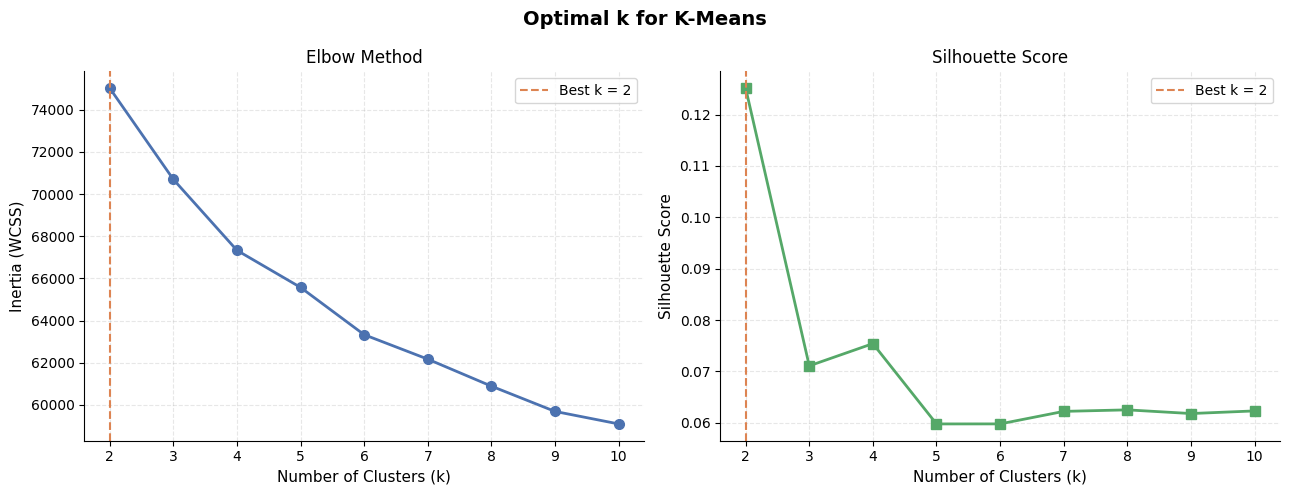

In [51]:
K_RANGE = range(2, 11)
inertias, sil_scores = [], []

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(Xtrain_scaled_df)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(Xtrain_scaled_df, lbl))

best_k = list(K_RANGE)[int(np.argmax(sil_scores))]
print(f'Best k (highest silhouette): {best_k}')

k_vals = list(K_RANGE)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Optimal k for K-Means', fontsize=14, fontweight='bold')

ax1.plot(k_vals, inertias, 'o-', color='#4C72B0', linewidth=2, markersize=7)
ax1.axvline(best_k, color='#DD8452', linestyle='--', linewidth=1.5, label=f'Best k = {best_k}')
ax1.set_title('Elbow Method', fontsize=12)
ax1.set_xlabel('Number of Clusters (k)', fontsize=11)
ax1.set_ylabel('Inertia (WCSS)', fontsize=11)
ax1.legend(fontsize=10)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(linestyle='--', alpha=0.3)

ax2.plot(k_vals, sil_scores, 's-', color='#55A868', linewidth=2, markersize=7)
ax2.axvline(best_k, color='#DD8452', linestyle='--', linewidth=1.5, label=f'Best k = {best_k}')
ax2.set_title('Silhouette Score', fontsize=12)
ax2.set_xlabel('Number of Clusters (k)', fontsize=11)
ax2.set_ylabel('Silhouette Score', fontsize=11)
ax2.legend(fontsize=10)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [52]:
# Fit K-Means with optimal k = 2 (selected by silhouette score)
km_final = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_labels = km_final.fit_predict(Xtrain_scaled_df)

train_clustered = train.copy()
train_clustered['Cluster'] = cluster_labels

print('Cluster distribution:')
print(pd.Series(cluster_labels).value_counts().sort_index())
print()
print('Cluster vs original Label cross-tab:')
print(pd.crosstab(train_clustered['Cluster'], train_clustered['Label'], 
                   rownames=['Cluster'], colnames=['Label']))

Cluster distribution:
0    209
1    268
Name: count, dtype: int64

Cluster vs original Label cross-tab:
Label      0   1
Cluster         
0        158  51
1        201  67


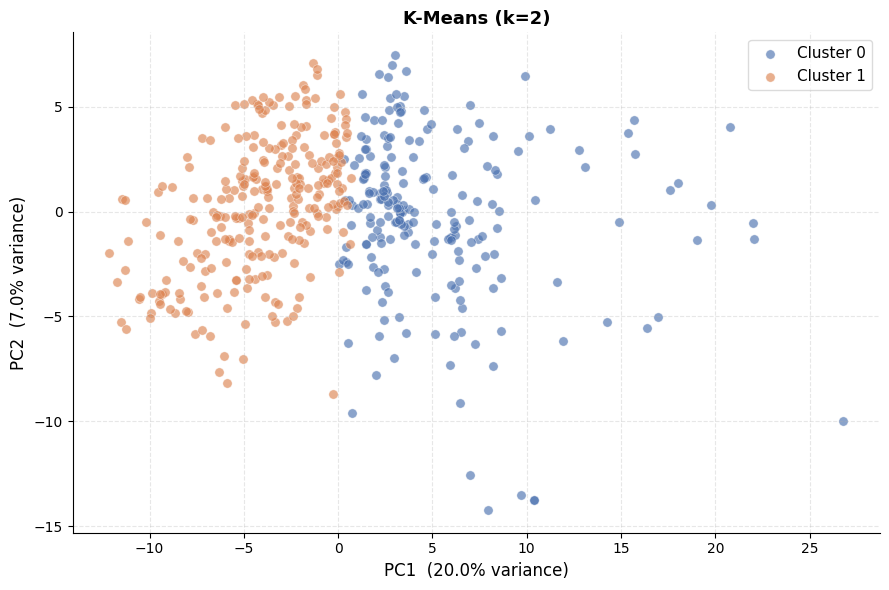

In [53]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(Xtrain_scaled_df)
var_exp = pca.explained_variance_ratio_ * 100

PALETTE = ['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2','#937860','#DA8BC3','#8C8C8C','#CCB974','#64B5CD']

fig, ax = plt.subplots(figsize=(9, 6))
for c in range(2):
    mask = (cluster_labels == c)
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=PALETTE[c],
               label=f'Cluster {c}', alpha=0.65, s=45, edgecolors='white', linewidths=0.4)

ax.set_xlabel(f'PC1  ({var_exp[0]:.1f}% variance)', fontsize=12)
ax.set_ylabel(f'PC2  ({var_exp[1]:.1f}% variance)', fontsize=12)
ax.set_title(f'K-Means (k=2)', fontsize=13, fontweight='bold')
ax.legend(fontsize=11, framealpha=0.7)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [54]:
dt = DecisionTreeClassifier(max_depth=4, random_state=42, min_samples_leaf=10)
dt.fit(Xtrain_scaled_df, cluster_labels)
dt_preds = dt.predict(Xtrain_scaled_df)
dt_acc = (dt_preds == cluster_labels).mean()
print(f'Decision Tree accuracy in reproducing clusters: {dt_acc:.4f} ({dt_acc*100:.1f}%)')
print('(Higher = tree explains clusters well)')

Decision Tree accuracy in reproducing clusters: 0.9686 (96.9%)
(Higher = tree explains clusters well)


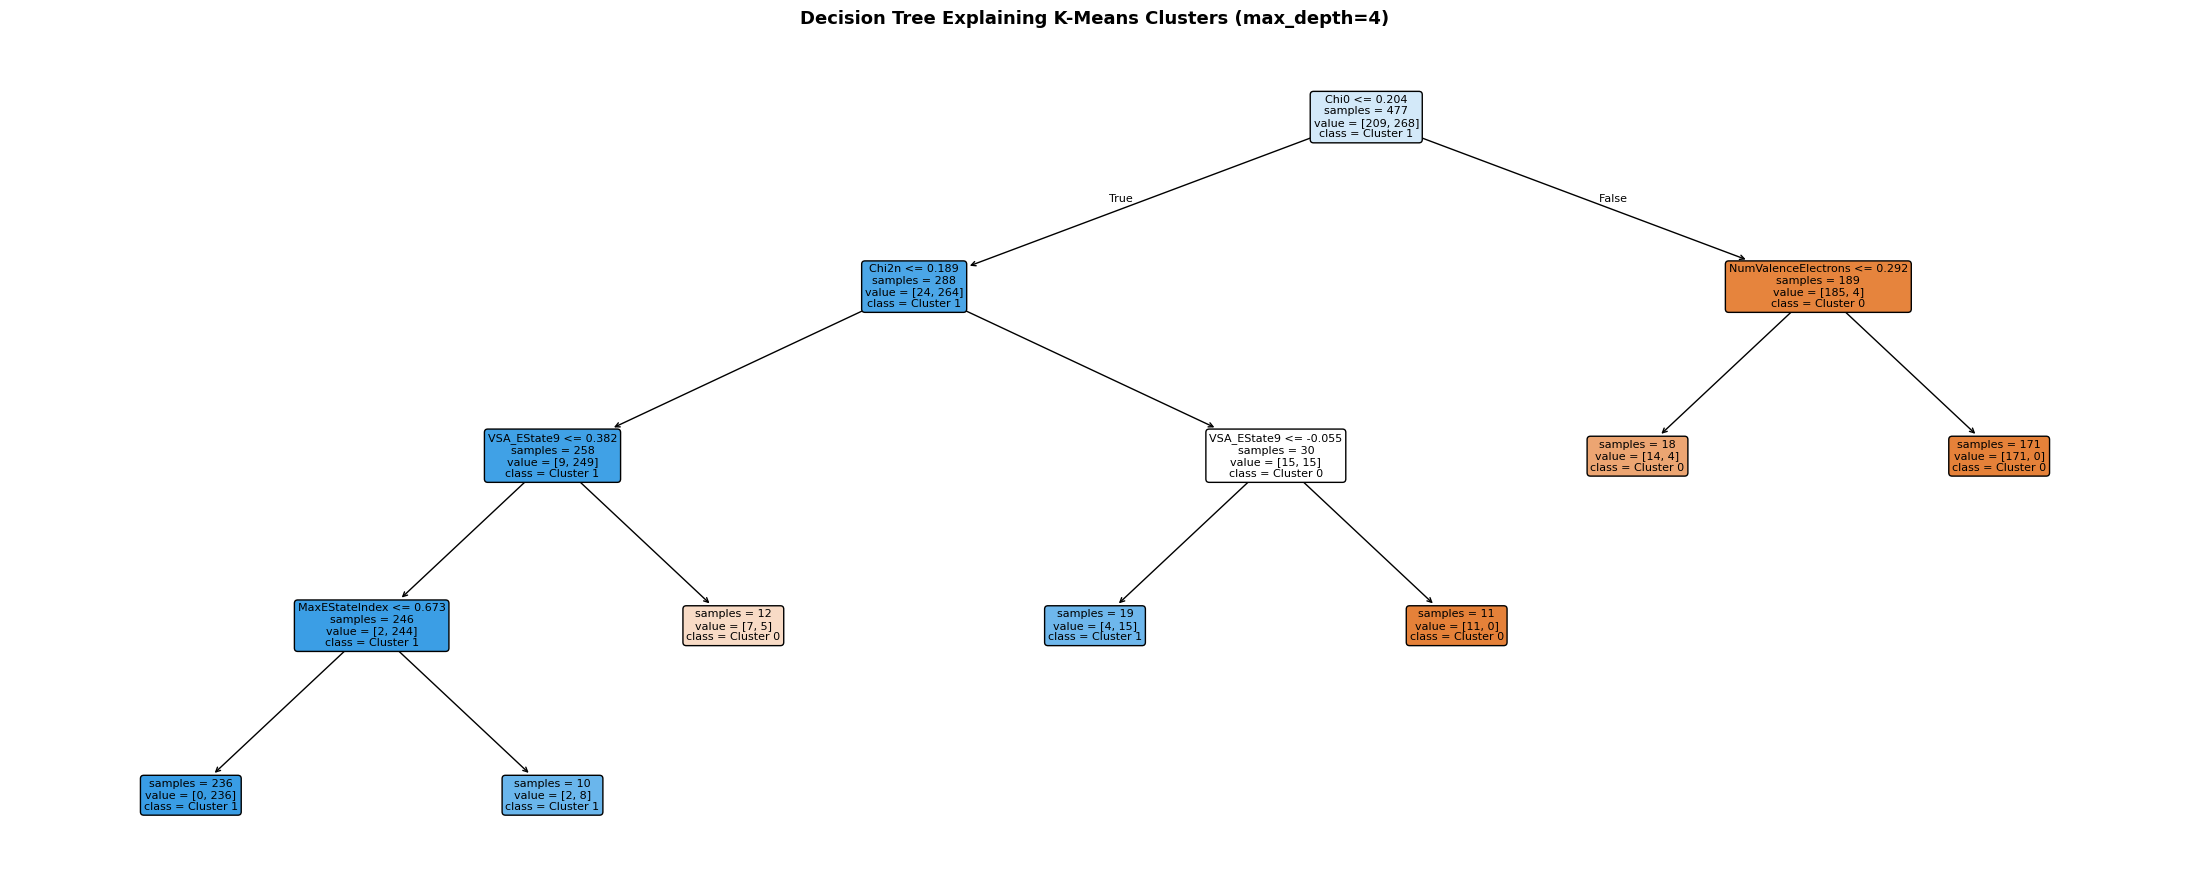

In [55]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(
    dt,
    feature_names=Xtrain_scaled_df.columns.tolist(),
    class_names=[f'Cluster {i}' for i in range(2)],
    filled=True, rounded=True, fontsize=8, ax=ax,
    impurity=False, proportion=False
)
ax.set_title('Decision Tree Explaining K-Means Clusters (max_depth=4)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

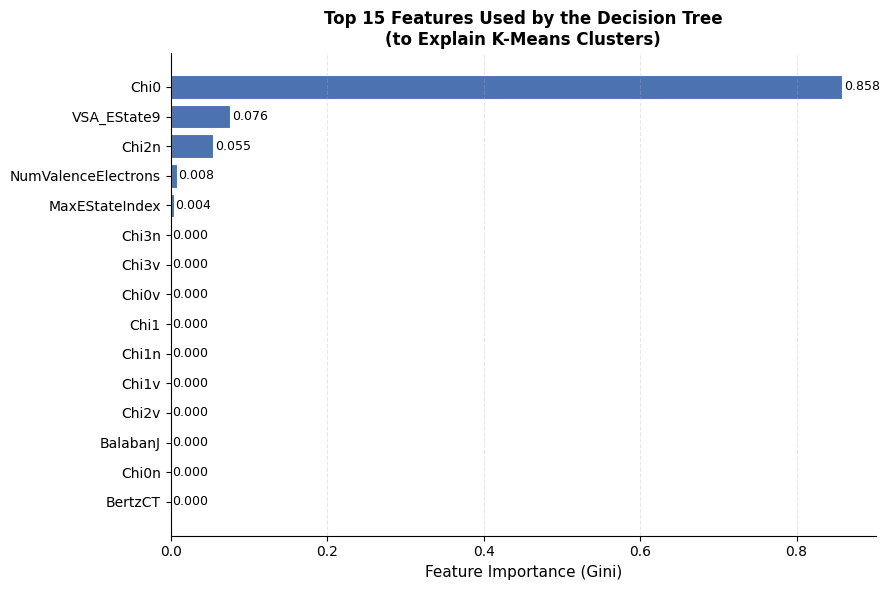


Top 5 most important features for cluster separation:
Chi0                   0.858124
VSA_EState9            0.076217
Chi2n                  0.054519
NumValenceElectrons    0.007542
MaxEStateIndex         0.003598


In [56]:
feat_imp = pd.Series(dt.feature_importances_, index=Xtrain_scaled_df.columns)
top15 = feat_imp.nlargest(15).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top15.index, top15.values, color='#4C72B0', edgecolor='white', linewidth=0.8)
ax.set_xlabel('Feature Importance (Gini)', fontsize=11)
ax.set_title('Top 15 Features Used by the Decision Tree\n(to Explain K-Means Clusters)', fontsize=12, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.3)
for bar, val in zip(bars, top15.values):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

print('\nTop 5 most important features for cluster separation:')
print(feat_imp.nlargest(5).to_string())

**Problem Statement:** Given the 196 RDKit molecular descriptors of a drug compound, predict whether it is likely to induce autoimmune disease (**DIA = 1**) or not (**Non-DIA = 0**).

This is a **binary supervised classification** task:
- **Input (X):** 196 scaled numerical molecular features
- **Target (y):** `Label` — 0 (Non-DIA) or 1 (DIA)
- **Challenge:** Class imbalance (~3:1 Non-DIA:DIA); handled via `class_weight='balanced'` in the classifier.

In [57]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve, ConfusionMatrixDisplay)

rf = RandomForestClassifier(n_estimators=200, random_state=42,
                             class_weight='balanced', n_jobs=-1)
rf.fit(Xtrain_scaled_df, Ytrain)

y_pred  = rf.predict(Xtest_scaled_df)
y_proba = rf.predict_proba(Xtest_scaled_df)[:, 1]
roc_auc = roc_auc_score(Ytest, y_proba)

print(f'Test ROC-AUC: {roc_auc:.4f}')
print()
print(classification_report(Ytest, y_pred, target_names=['Non-DIA', 'DIA']))

Test ROC-AUC: 0.9117

              precision    recall  f1-score   support

     Non-DIA       0.80      0.99      0.89        90
         DIA       0.89      0.27      0.41        30

    accuracy                           0.81       120
   macro avg       0.85      0.63      0.65       120
weighted avg       0.82      0.81      0.77       120



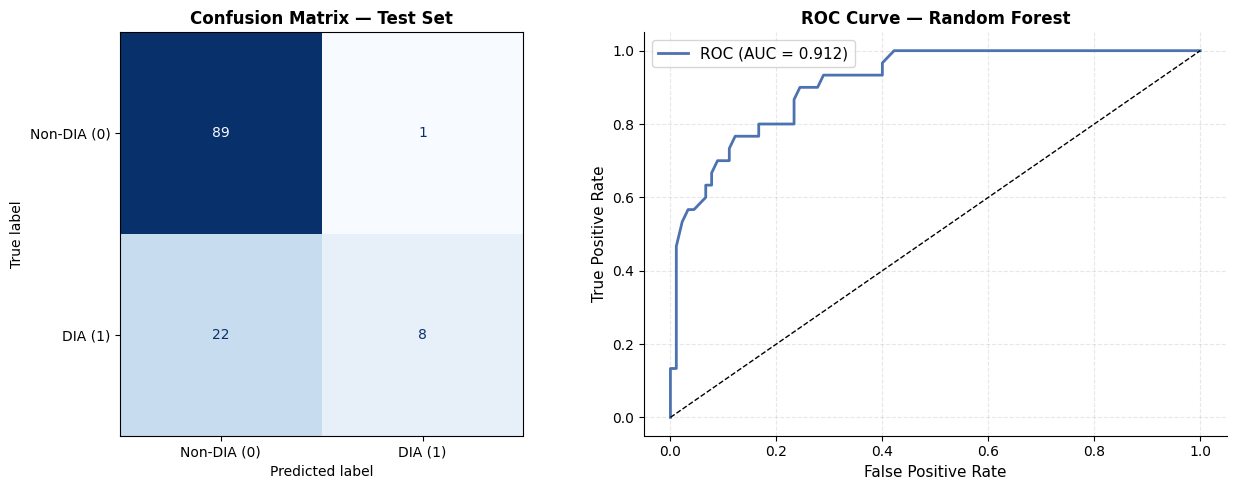

In [58]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion matrix
cm = confusion_matrix(Ytest, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-DIA (0)', 'DIA (1)'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix — Test Set', fontsize=12, fontweight='bold')

# ROC curve
fpr, tpr, _ = roc_curve(Ytest, y_proba)
axes[1].plot(fpr, tpr, color='#4C72B0', lw=2, label=f'ROC (AUC = {roc_auc:.3f})')
axes[1].plot([0,1],[0,1], 'k--', lw=1)
axes[1].set_xlabel('False Positive Rate', fontsize=11)
axes[1].set_ylabel('True Positive Rate', fontsize=11)
axes[1].set_title('ROC Curve — Random Forest', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].grid(linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

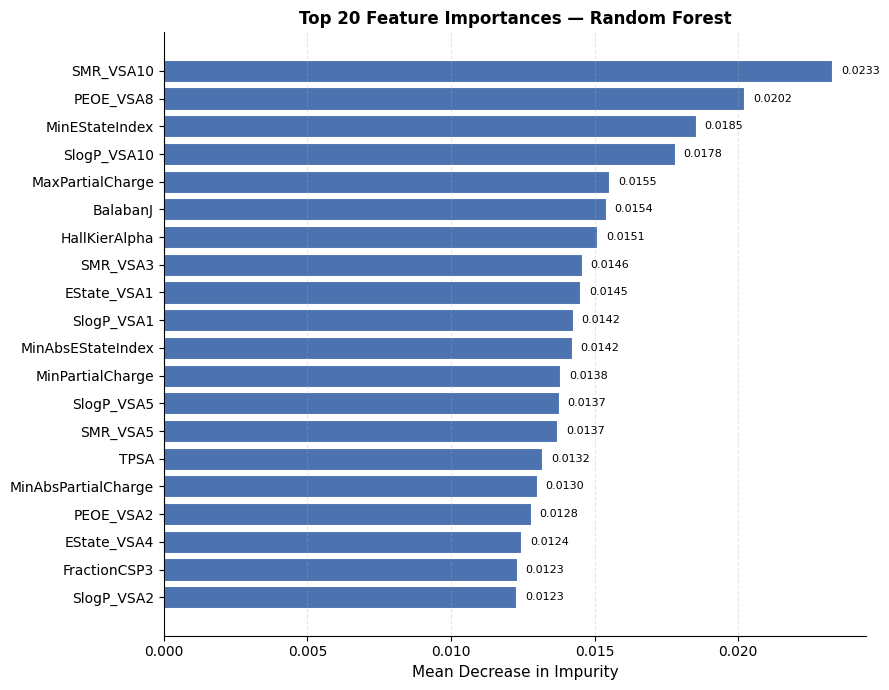

In [59]:
# RF built-in feature importances (MDI)
feat_imp = pd.Series(rf.feature_importances_, index=Xtrain_scaled_df.columns)
top20 = feat_imp.nlargest(20).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(top20.index, top20.values, color='#4C72B0', edgecolor='white', linewidth=0.8)
ax.set_xlabel('Mean Decrease in Impurity', fontsize=11)
ax.set_title('Top 20 Feature Importances — Random Forest', fontsize=12, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.3)
for bar, val in zip(bars, top20.values):
    ax.text(bar.get_width() + 0.0003, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=8)
plt.tight_layout()
plt.show()

In [60]:
import shap

# TreeExplainer is exact and fast for Random Forests
explainer_shap = shap.TreeExplainer(rf)
shap_values_train = explainer_shap(Xtrain_scaled_df)

# Class 1 (DIA) SHAP values
shap_vals_class1 = shap_values_train[:, :, 1]
print('SHAP values computed. Shape:', shap_vals_class1.shape)

SHAP values computed. Shape: (477, 196)


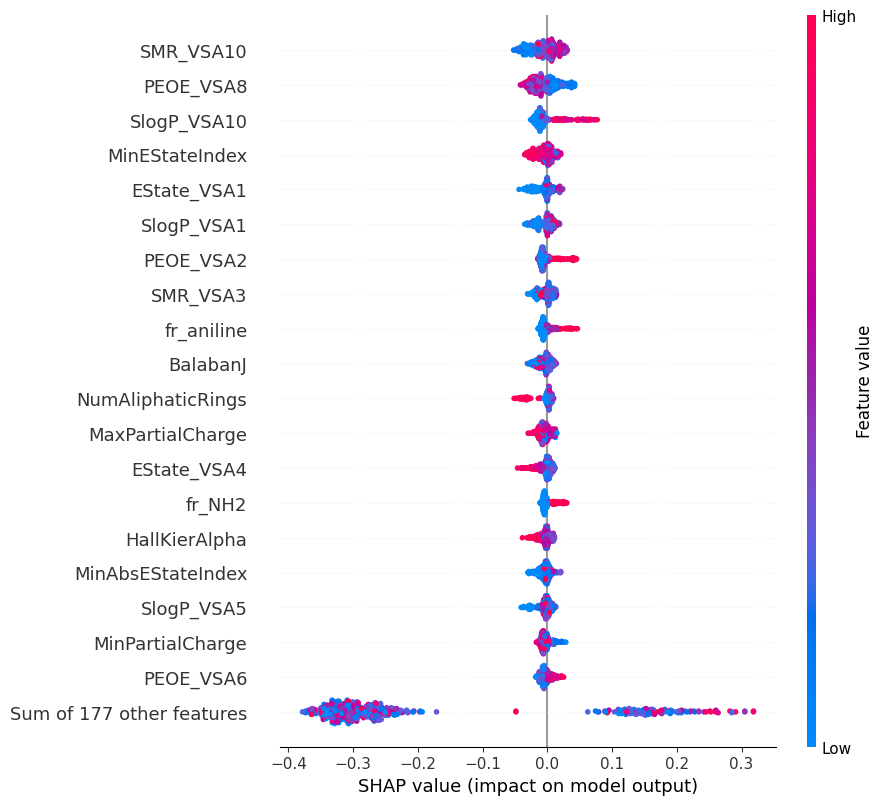

In [61]:
# Beeswarm — global feature impact (DIA class)
shap.plots.beeswarm(shap_vals_class1, max_display=20)

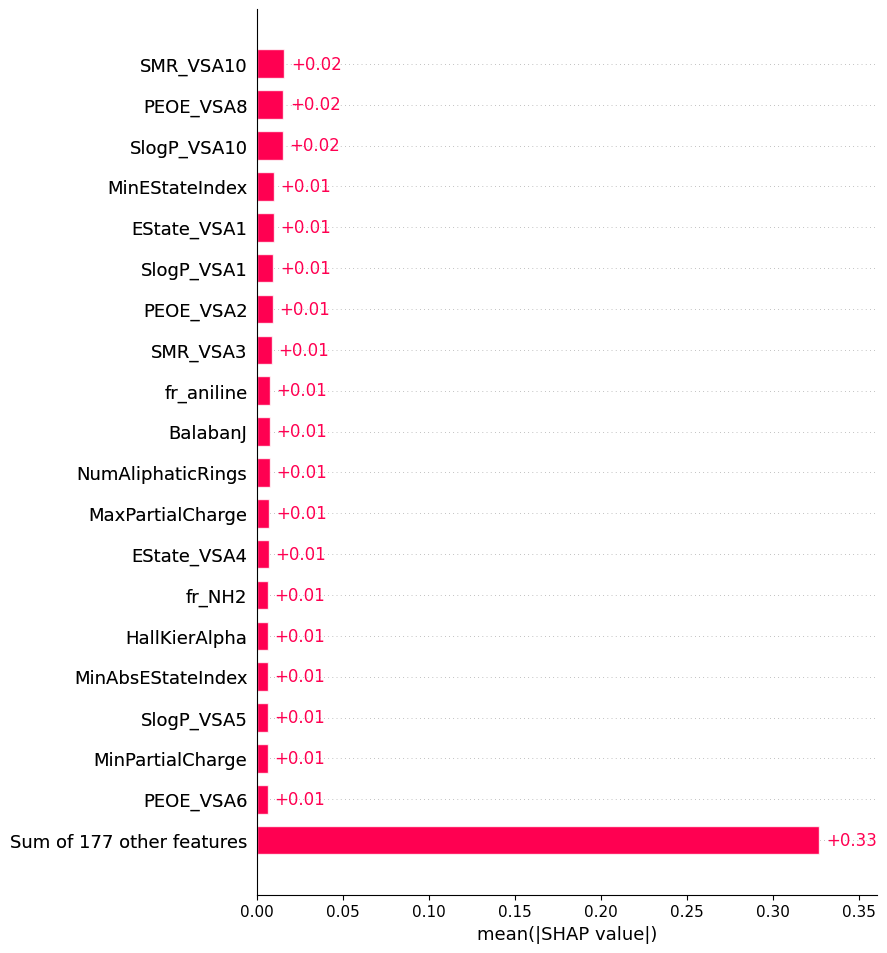

In [62]:
# Bar summary — mean |SHAP| per feature
shap.plots.bar(shap_vals_class1, max_display=20)

Waterfall for training sample #3 (True DIA):


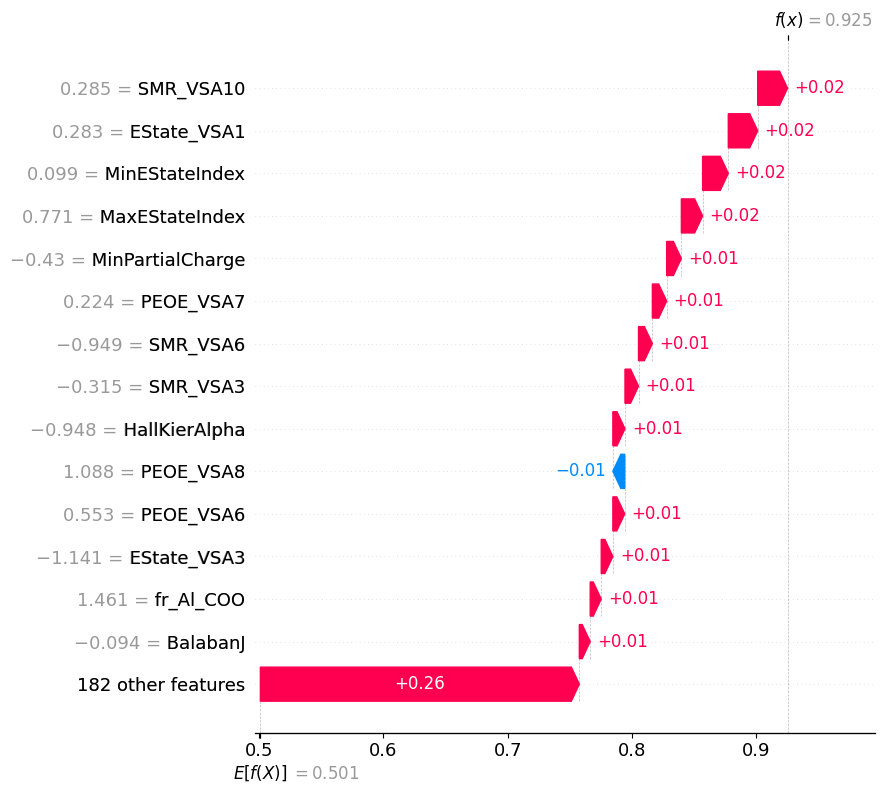


Waterfall for training sample #0 (True Non-DIA):


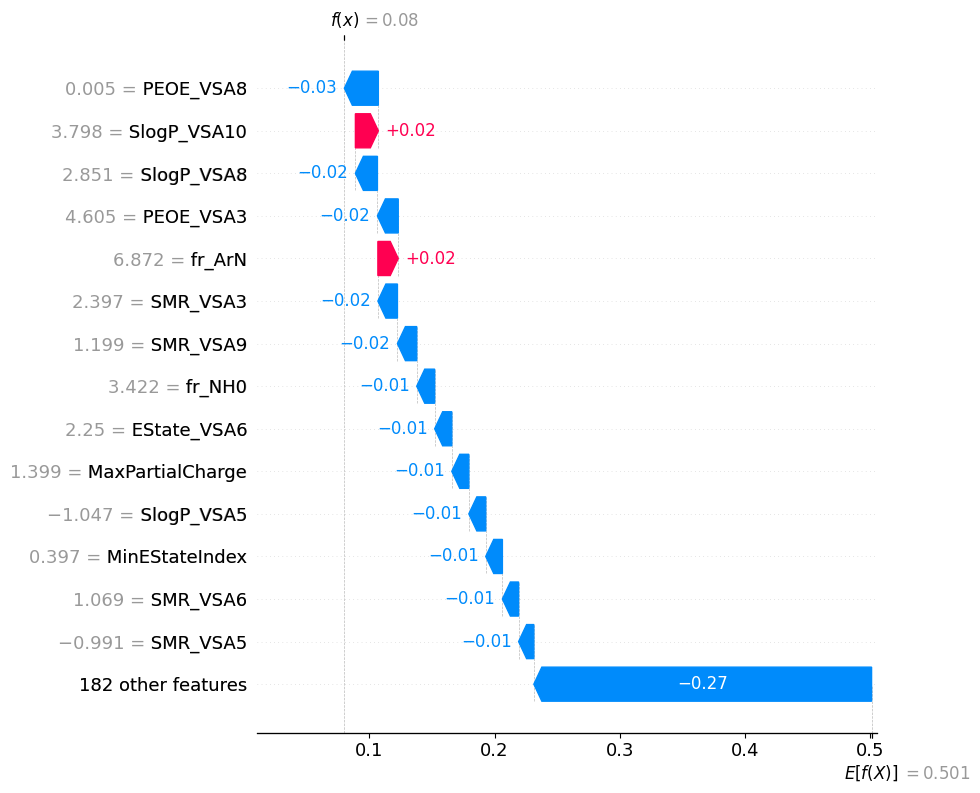

In [63]:
# Waterfall — local explanation for a single DIA sample
dia_idx     = int(np.where(Ytrain.values == 1)[0][0])
non_dia_idx = int(np.where(Ytrain.values == 0)[0][0])

print(f'Waterfall for training sample #{dia_idx} (True DIA):')
shap.plots.waterfall(shap_vals_class1[dia_idx], max_display=15)

print(f'\nWaterfall for training sample #{non_dia_idx} (True Non-DIA):')
shap.plots.waterfall(shap_vals_class1[non_dia_idx], max_display=15)

In [64]:
import lime
import lime.lime_tabular

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    Xtrain_scaled,
    feature_names=Xtrain.columns.tolist(),
    class_names=['Non-DIA', 'DIA'],
    mode='classification',
    random_state=42
)
print('LIME explainer ready.')

LIME explainer ready.


In [65]:
# LIME explanation for first test sample
exp0 = lime_explainer.explain_instance(
    Xtest_scaled[0], rf.predict_proba, num_features=15, top_labels=1
)
print(f'Test sample 0 — True: {Ytest.values[0]}, Predicted: {y_pred[0]}')
exp0.show_in_notebook(show_table=True)

Test sample 0 — True: 0, Predicted: 0


d:\Programs\MiniConda\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning:

X does not have valid feature names, but RandomForestClassifier was fitted with feature names



In [66]:
# LIME explanation for a true DIA sample from the test set
dia_test_idx = int(np.where(Ytest.values == 1)[0][0])
exp_dia = lime_explainer.explain_instance(
    Xtest_scaled[dia_test_idx], rf.predict_proba, num_features=15, top_labels=1
)
print(f'Test sample {dia_test_idx} — True: DIA (1), Predicted: {["Non-DIA","DIA"][y_pred[dia_test_idx]]}')
exp_dia.show_in_notebook(show_table=True)

Test sample 1 — True: DIA (1), Predicted: DIA


d:\Programs\MiniConda\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning:

X does not have valid feature names, but RandomForestClassifier was fitted with feature names



# Shapash — SmartExplainer Dashboard
[Shapash](https://github.com/MAIF/shapash) is a MAIF library that wraps SHAP into a polished, interactive dashboard.

In [67]:
from shapash import SmartExplainer

xpl = SmartExplainer(
    model=rf,
    features_dict={col: col for col in Xtrain_scaled_df.columns}
)
xpl.compile(
    x=Xtrain_scaled_df,
    y_target=Ytrain,
)
print('SmartExplainer compiled successfully.')

INFO: Shap explainer type - <shap.explainers._tree.TreeExplainer object at 0x000002474DE28F20>
SmartExplainer compiled successfully.


In [68]:
# Global feature importance (Shapash wraps SHAP, presents it cleanly)
xpl.plot.features_importance(max_features=20)

In [69]:
# Local explanation — DIA sample
print(f'Local explanation for training sample #{dia_idx} (True DIA):')
xpl.plot.local_plot(index=dia_idx)

Local explanation for training sample #3 (True DIA):


In [70]:
# Local explanation — Non-DIA sample
print(f'Local explanation for training sample #{non_dia_idx} (True Non-DIA):')
xpl.plot.local_plot(index=non_dia_idx)

Local explanation for training sample #0 (True Non-DIA):


In [71]:
# Summary table: top contributing features per sample
summary_df = xpl.to_pandas(max_contrib=5)
print('Shapash summary table (top 5 features per sample):')
summary_df.head(10)

Shapash summary table (top 5 features per sample):


,pred,feature_1,value_1,contribution_1,feature_2,value_2,contribution_2,feature_3,value_3,contribution_3,feature_4,value_4,contribution_4,feature_5,value_5,contribution_5
0,0,PEOE_VSA8,0.005257,0.027137,SlogP_VSA10,3.798498,-0.018329,SlogP_VSA8,2.851332,0.017595,PEOE_VSA3,4.605039,0.016623,fr_ArN,6.871798,-0.016254
1,0,SlogP_VSA10,0.184222,0.014793,fr_thiophene,5.551415,0.014385,PEOE_VSA10,-0.898272,0.013686,MaxPartialCharge,0.715441,0.01271,EState_VSA8,-0.948309,0.012247
2,0,SlogP_VSA5,-1.262206,0.028524,Chi3n,-1.54792,0.019521,SMR_VSA5,-1.188299,0.018932,SMR_VSA10,-0.869567,0.018863,SMR_VSA3,-0.929289,0.01529
3,1,SMR_VSA10,0.28545,0.02402,EState_VSA1,0.283293,0.023643,MinEStateIndex,0.098875,0.02065,MaxEStateIndex,0.770782,0.017097,MinPartialCharge,-0.429526,0.011817
4,1,SlogP_VSA10,2.52527,0.048577,PEOE_VSA8,-0.893295,0.030054,EState_VSA1,0.474686,0.018652,fr_aniline,1.00037,0.01394,FractionCSP3,-1.209993,0.011941
5,0,PEOE_VSA8,2.570043,0.022397,EState_VSA3,3.752767,0.019103,EState_VSA4,1.146947,0.018377,SMR_VSA6,1.689087,0.016277,PEOE_VSA9,2.384207,0.015493
6,0,EState_VSA9,2.070976,0.033072,EState_VSA3,1.379155,0.027684,PEOE_VSA9,2.382307,0.023477,SlogP_VSA10,-0.613938,0.02228,EState_VSA6,2.080527,0.0184
7,1,MinAbsEStateIndex,-0.016136,0.019758,SlogP_VSA1,0.469134,0.018435,Chi3v,-0.804049,0.016225,EState_VSA1,-0.524655,0.015981,PEOE_VSA8,-0.420769,0.015516
8,0,EState_VSA3,1.556573,0.038552,PEOE_VSA8,0.865527,0.028519,EState_VSA4,1.08956,0.026833,RingCount,1.298829,0.026207,fr_piperdine,1.88113,0.016712
9,0,EState_VSA4,2.501602,0.041091,BalabanJ,-1.038649,0.029532,SMR_VSA9,2.090558,0.027544,PEOE_VSA7,1.722781,0.023897,SlogP_VSA11,3.108365,0.019884


In [72]:
# ── Launch interactive Shapash web app ────────────────────────────────────
# Uncomment the line below to launch the interactive Dash dashboard.
# It opens at http://localhost:8050 in your browser.
# xpl.run_app(port=8050)

In [73]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_smote, Y_smote = smote.fit_resample(Xtrain_scaled_df, Ytrain)
X_smote_df = pd.DataFrame(X_smote, columns=Xtrain.columns)

print('Before SMOTE:', dict(Ytrain.value_counts().sort_index()))
print('After  SMOTE:', dict(pd.Series(Y_smote).value_counts().sort_index()))

Before SMOTE: {0: np.int64(359), 1: np.int64(118)}
After  SMOTE: {0: np.int64(359), 1: np.int64(359)}


In [74]:
rf_smote = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_smote.fit(X_smote_df, Y_smote)

y_pred_s  = rf_smote.predict(Xtest_scaled_df)
y_proba_s = rf_smote.predict_proba(Xtest_scaled_df)[:, 1]
roc_auc_s = roc_auc_score(Ytest, y_proba_s)

print(f'Test ROC-AUC (SMOTE RF): {roc_auc_s:.4f}')
print()
print(classification_report(Ytest, y_pred_s, target_names=['Non-DIA', 'DIA']))

Test ROC-AUC (SMOTE RF): 0.9157

              precision    recall  f1-score   support

     Non-DIA       0.87      0.98      0.92        90
         DIA       0.89      0.57      0.69        30

    accuracy                           0.88       120
   macro avg       0.88      0.77      0.81       120
weighted avg       0.88      0.88      0.86       120



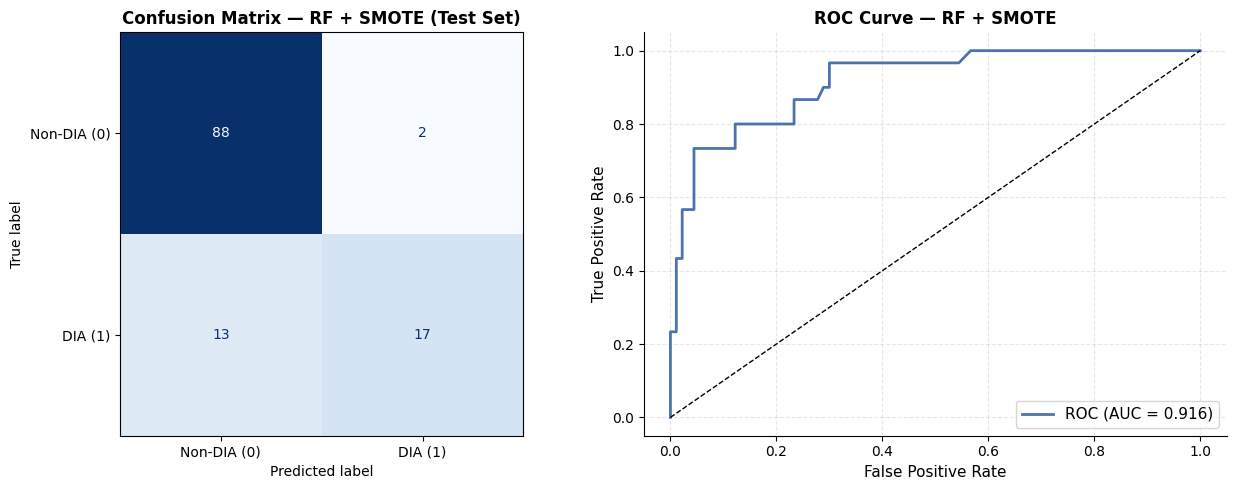

In [75]:
cm_s = confusion_matrix(Ytest, y_pred_s)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

disp = ConfusionMatrixDisplay(confusion_matrix=cm_s, display_labels=['Non-DIA (0)', 'DIA (1)'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix — RF + SMOTE (Test Set)', fontsize=12, fontweight='bold')

fpr, tpr, _ = roc_curve(Ytest, y_proba_s)
axes[1].plot(fpr, tpr, color='#4C72B0', lw=2, label=f'ROC (AUC = {roc_auc_s:.3f})')
axes[1].plot([0,1],[0,1], 'k--', lw=1)
axes[1].set_xlabel('False Positive Rate', fontsize=11)
axes[1].set_ylabel('True Positive Rate', fontsize=11)
axes[1].set_title('ROC Curve — RF + SMOTE', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].grid(linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [76]:
dia_idx     = int(np.where(Y_smote == 1)[0][0])
non_dia_idx = int(np.where(Y_smote == 0)[0][0])

xpl = SmartExplainer(
    model=rf_smote,
    features_dict={col: col for col in X_smote_df.columns}
)
xpl.compile(x=X_smote_df, y_target=pd.Series(Y_smote))
print('SmartExplainer compiled.')

INFO: Shap explainer type - <shap.explainers._tree.TreeExplainer object at 0x0000024745C7CF20>
SmartExplainer compiled.


In [77]:
xpl.plot.features_importance(max_features=20)

In [78]:
xpl.plot.local_plot(index=dia_idx)

In [79]:
xpl.plot.local_plot(index=non_dia_idx)

In [80]:
summary_df = xpl.to_pandas(max_contrib=5)
summary_df.head(10)

,pred,feature_1,value_1,contribution_1,feature_2,value_2,contribution_2,feature_3,value_3,contribution_3,feature_4,value_4,contribution_4,feature_5,value_5,contribution_5
0,0,MaxPartialCharge,1.398748,0.024854,SlogP_VSA5,-1.047197,0.022738,SMR_VSA9,1.199439,0.020599,MinAbsPartialCharge,1.551494,0.020556,RingCount,0.700238,0.019722
1,0,MaxPartialCharge,0.715441,0.045502,EState_VSA5,-0.915263,0.026333,fr_aniline,-0.529042,0.02345,fr_NH1,-0.685566,0.020018,NumAliphaticRings,-0.9295,0.01905
2,0,SlogP_VSA5,-1.262206,0.037259,SMR_VSA3,-0.929289,0.02575,SMR_VSA5,-1.188299,0.022806,NumAromaticRings,-1.238078,0.01918,PEOE_VSA6,-1.138449,0.017221
3,1,fr_COO,1.315288,0.028393,fr_COO2,1.289878,0.027208,SMR_VSA3,-0.315029,0.02175,fr_Al_COO,1.460615,0.020741,NHOHCount,0.376545,0.01932
4,1,SlogP_VSA10,2.52527,0.036682,fr_aniline,1.00037,0.029142,fr_amide,0.511766,0.015876,EState_VSA1,0.474686,0.014029,SMR_VSA3,-0.929289,-0.013731
5,0,MaxPartialCharge,1.343344,0.030966,RingCount,1.298829,0.028785,EState_VSA3,3.752767,0.023292,BalabanJ,-1.218888,0.022171,MinAbsPartialCharge,1.491982,0.019813
6,0,MaxPartialCharge,0.687739,0.030757,NHOHCount,-0.571275,0.027978,PEOE_VSA9,2.382307,0.024709,EState_VSA3,1.379155,0.019703,MinAbsPartialCharge,0.787755,0.018494
7,1,SMR_VSA3,-0.214154,0.019638,BalabanJ,0.076575,0.017273,NHOHCount,-0.097365,0.017231,fr_NH1,0.525601,0.016935,SlogP_VSA1,0.469134,0.016833
8,0,EState_VSA3,1.556573,0.035505,RingCount,1.298829,0.034199,MaxPartialCharge,0.733909,0.025548,EState_VSA4,1.08956,0.024241,fr_piperdine,1.88113,0.020459
9,0,EState_VSA4,2.501602,0.042385,BalabanJ,-1.038649,0.03555,SMR_VSA9,2.090558,0.033783,SlogP_VSA11,3.108365,0.028308,RingCount,0.700238,0.027291


In [81]:
# xpl.run_app(port=8050)